## Modelisation

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from pathlib import Path

In [3]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent
DATA_FILE = ROOT / "data"
MODELS_DIR = ROOT / "models"

df = pd.read_csv(DATA_FILE / "dataset_consolide.csv")
train = df.loc[df["Year"] <= 2009]

# Couples (pays, culture) présents dans les données d'entraînement
references_pays_cultures = (
    train.groupby(["Area", "Crop"]).size()
    .rename("nb_annees")
    .reset_index()
)
display(references_pays_cultures.head())
print(len(references_pays_cultures), "couples pays-culture")
references_pays_cultures.to_csv(MODELS_DIR / "references_pays_cultures.csv", index=False)

,Area,Crop,nb_annees
0,Albania,Maize,20
1,Albania,Potatoes,20
2,Albania,Rice,4
3,Albania,Sorghum,3
4,Albania,Soybean,20


703 couples pays-culture


In [2]:
ROOT = Path.cwd().parent
DATA_FILE = ROOT/"data"

df = pd.read_csv(DATA_FILE/ "dataset_consolide.csv")
display(df)

,Area,Crop,Year,yield_t_ha,average_rain_fall_mm_per_year,avg_temp,log_pesticides,I_DeMartonne,temp_sqr
0,Albania,Maize,1990,3.6613,1485.0,16.37,4.804021,56.313993,267.9769
1,Albania,Maize,1991,2.9068,1485.0,15.36,4.804021,58.556782,235.9296
2,Albania,Maize,1992,2.4876,1485.0,16.06,4.804021,56.983883,257.9236
3,Albania,Maize,1993,2.4185,1485.0,16.05,4.804021,57.005758,257.6025
4,Albania,Maize,1994,2.5848,1485.0,16.96,5.308268,55.081602,287.6416
...,...,...,...,...,...,...,...,...,...
16392,Zimbabwe,Wheat,2009,3.0000,657.0,20.52,8.092848,21.526868,421.0704
16393,Zimbabwe,Wheat,2010,2.7681,657.0,21.17,8.103546,21.077960,448.1689
16394,Zimbabwe,Wheat,2011,2.6274,657.0,20.78,8.114130,21.345029,431.8084
16395,Zimbabwe,Wheat,2012,2.4420,657.0,20.52,8.124604,21.526868,421.0704


In [3]:
#Mise en place du experiment tracking
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("P12_rendement_cultures")

2026/11/20 13:38:34 INFO mlflow.tracking.fluent: Experiment with name 'P12_rendement_cultures' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1795178314926, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1795178314926, lifecycle_stage='active', name='P12_rendement_cultures', tags={}, trace_location=None, workspace='default'>

In [4]:
cible = df["yield_t_ha"]
numerics = [["Year", "average_rain_fall_mm_per_year", "avg_temp", "log_pesticides", "I_DeMartonne", "temp_sqr"]]
categoricals = ["Crop"]

Nous allons réaliser un split temporel.

In [ ]:
#Entrainement des différents modèles + split temporel du dataset pour pourvoir observer la capacité d'adaptation aux années futures.
import mlflow
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

SEED = 42

#Variables et split temporel
cible = "yield_t_ha"
numerics = ["Year", "log_pesticides", "average_rain_fall_mm_per_year", "avg_temp", "temp_sqr", "I_DeMartonne"]
categoricals = ["Crop"]

# Train trié par année pour que TimeSeriesSplit crée des plis chronologiques
train = df.loc[df["Year"] <= 2009].sort_values("Year").reset_index(drop=True)
test = df.loc[df["Year"] >= 2010].reset_index(drop=True)

X_train, y_train = train[numerics + categoricals], train[cible]
X_test, y_test = test[numerics + categoricals], test[cible]

#Preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerics),
    ("cat", categorical_pipeline, categoricals),
])

#Validation croisée temporelle et métriques
cv = TimeSeriesSplit(n_splits=5)
scoring = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}

modeles = {
    "Dummy": DummyRegressor(strategy="mean"),
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(random_state=SEED, n_jobs=-1),
    "XGBoost": XGBRegressor(random_state=SEED, n_jobs=-1),
    "LightGBM": LGBMRegressor(random_state=SEED, verbose=-1),
}

#Comparaison des modèles, enregistrée dans MLflow
resultats = {}
for nom, modele in modeles.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("modele", modele)])

    with mlflow.start_run(run_name=f"comparaison_{nom}"):
        scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)

        metriques = {
            "RMSE_train": -scores["train_RMSE"].mean(),
            "RMSE_val": -scores["test_RMSE"].mean(),
            "MAE_train": -scores["train_MAE"].mean(),
            "MAE_val": -scores["test_MAE"].mean(),
            "R2_train": scores["train_R2"].mean(),
            "R2_val": scores["test_R2"].mean(),
        }

        mlflow.set_tag("etape", "comparaison_modeles")
        mlflow.set_tag("validation", "TimeSeriesSplit_5")
        mlflow.log_param("modele", nom)
        mlflow.log_param("variables", ", ".join(numerics + categoricals))
        mlflow.log_params(modele.get_params())
        mlflow.log_metrics(metriques)

    resultats[nom] = metriques

df_resultats = pd.DataFrame(resultats).T.sort_values("RMSE_val")
display(df_resultats.round(3))


#Baseline par culture (moyenne du rendement de chaque culture)
with mlflow.start_run(run_name="baseline_moyenne_par_culture"):
    plis = []
    for idx_train, idx_val in cv.split(X_train):
        moyennes = y_train.iloc[idx_train].groupby(X_train["Crop"].iloc[idx_train]).mean()
        y_pred = X_train["Crop"].iloc[idx_val].map(moyennes)
        y_vrai = y_train.iloc[idx_val]
        plis.append({
            "RMSE_val": root_mean_squared_error(y_vrai, y_pred),
            "MAE_val": mean_absolute_error(y_vrai, y_pred),
            "R2_val": r2_score(y_vrai, y_pred),
        })
    metriques_baseline = pd.DataFrame(plis).mean().to_dict()

    mlflow.set_tag("etape", "comparaison_modeles")
    mlflow.set_tag("validation", "TimeSeriesSplit_5")
    mlflow.log_param("modele", "MoyenneParCulture")
    mlflow.log_metrics(metriques_baseline)

print("Baseline par culture :", {k: round(v, 3) for k, v in metriques_baseline.items()})

🏃 View run comparaison_Dummy at: http://127.0.0.1:5000/#/experiments/1/runs/5e04bae3944f49708109e28d5067420f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run comparaison_LinearRegression at: http://127.0.0.1:5000/#/experiments/1/runs/49c06e4fb7f242b3a8b518c92b192c7f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run comparaison_RandomForest at: http://127.0.0.1:5000/#/experiments/1/runs/5c4f55373f684056949515f575bcacbe
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run comparaison_XGBoost at: http://127.0.0.1:5000/#/experiments/1/runs/fbcb575c10a040b08dd6842532a2a536
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run comparaison_LightGBM at: http://127.0.0.1:5000/#/experiments/1/runs/a837aa4adaef4d2d8fb4c705af5f32fb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,RMSE_train,RMSE_val,MAE_train,MAE_val,R2_train,R2_val
RandomForest,0.577,2.235,0.290,1.113,0.993,0.912
XGBoost,0.717,2.314,0.481,1.273,0.989,0.906
LightGBM,1.605,2.598,1.050,1.542,0.949,0.882
LinearRegression,4.414,4.743,2.836,3.010,0.612,0.608
Dummy,7.082,7.596,5.089,5.355,0.000,-0.006


🏃 View run baseline_moyenne_par_culture at: http://127.0.0.1:5000/#/experiments/1/runs/92c4038687ae4d2fab3addb2c439762b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Baseline par culture : {'RMSE_val': 5.192, 'MAE_val': 3.127, 'R2_val': 0.53}


In [ ]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold

#Fonction d'évaluation réutilisable
def evaluer_modele(nom_run, modele, numerics, categoricals, cv, etape, log_cible=False):
    preprocessor = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numerics),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categoricals),
    ])
    pipeline = Pipeline([("preprocessor", preprocessor), ("modele", modele)])

    if log_cible:
        # Entraînement sur log(1 + rendement), prédictions reconverties en t/ha
        pipeline = TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1)

    X = train[numerics + categoricals]
    with mlflow.start_run(run_name=nom_run):
        scores = cross_validate(pipeline, X, y_train, cv=cv, scoring=scoring, return_train_score=True)
        metriques = {
            "RMSE_train": -scores["train_RMSE"].mean(), "RMSE_val": -scores["test_RMSE"].mean(),
            "MAE_train": -scores["train_MAE"].mean(), "MAE_val": -scores["test_MAE"].mean(),
            "R2_train": scores["train_R2"].mean(), "R2_val": scores["test_R2"].mean(),
        }
        mlflow.set_tag("etape", etape)
        mlflow.set_tag("validation", type(cv).__name__)
        mlflow.log_param("modele", type(modele).__name__)
        mlflow.log_param("variables", ", ".join(numerics + categoricals))
        mlflow.log_param("log_cible", log_cible)
        mlflow.log_params(modele.get_params())
        mlflow.log_metrics(metriques)
    return metriques


#Définition des expériences
# Sans pluie : on retire aussi l'indice de De Martonne, calculé à partir de la pluie
numerics_sans_pluie = [v for v in numerics if v not in ["average_rain_fall_mm_per_year", "I_DeMartonne"]]

cv_temporel = TimeSeriesSplit(n_splits=5)
cv_aleatoire = KFold(n_splits=5, shuffle=True, random_state=SEED)

experiences = {
    "reference":            dict(numerics=numerics,            categoricals=["Crop"],         cv=cv_temporel,  log_cible=False),
    "sans_pluie":           dict(numerics=numerics_sans_pluie, categoricals=["Crop"],         cv=cv_temporel,  log_cible=False),
    "avec_pays":            dict(numerics=numerics,            categoricals=["Crop", "Area"], cv=cv_temporel,  log_cible=False),
    "avec_pays_sans_pluie": dict(numerics=numerics_sans_pluie, categoricals=["Crop", "Area"], cv=cv_temporel,  log_cible=False),
    "log_cible":            dict(numerics=numerics,            categoricals=["Crop"],         cv=cv_temporel,  log_cible=True),
    "split_aleatoire":      dict(numerics=numerics,            categoricals=["Crop"],         cv=cv_aleatoire, log_cible=False),
}

def creer_modeles():
    # Nouveaux objets à chaque appel, pour qu'aucun run n'hérite d'un modèle déjà entraîné
    return {
        "RandomForest": RandomForestRegressor(random_state=SEED, n_jobs=-1),
        "XGBoost": XGBRegressor(random_state=SEED, n_jobs=-1),
    }


#Lancement : 6 expériences x 2 modèles
resultats_exp = []
for nom_exp, config in experiences.items():
    for nom_modele, modele in creer_modeles().items():
        metriques = evaluer_modele(
            nom_run=f"{nom_exp}_{nom_modele}",
            modele=modele,
            numerics=config["numerics"],
            categoricals=config["categoricals"],
            cv=config["cv"],
            etape=f"experience_{nom_exp}",
            log_cible=config["log_cible"],
        )
        resultats_exp.append({"experience": nom_exp, "modele": nom_modele, **metriques})

df_exp = pd.DataFrame(resultats_exp).set_index(["experience", "modele"])
display(df_exp[["RMSE_train", "RMSE_val", "MAE_val", "R2_val"]].round(3))

🏃 View run reference_RandomForest at: http://127.0.0.1:5000/#/experiments/1/runs/05d749191d444451a611189d892d6d78
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run reference_XGBoost at: http://127.0.0.1:5000/#/experiments/1/runs/92ed54b21baf43388d9cc2f3f411f5f0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run sans_pluie_RandomForest at: http://127.0.0.1:5000/#/experiments/1/runs/37cafe088fa044f6b686bb31ae72ef7d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run sans_pluie_XGBoost at: http://127.0.0.1:5000/#/experiments/1/runs/79f7e2f9816849afbc88a1ccbe193260
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run avec_pays_RandomForest at: http://127.0.0.1:5000/#/experiments/1/runs/440476b77c6b451e990a93bab8a635ae
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run avec_pays_XGBoost at: http://127.0.0.1:5000/#/experiments/1/runs/51bdaec2b81549aaad74130bcf3b612d
🧪 View experiment at: http://

RMSE_train  RMSE_val  MAE_val  R2_val
experience           modele                                             
reference            RandomForest       0.577     2.235    1.113   0.912
                     XGBoost            0.717     2.314    1.273   0.906
sans_pluie           RandomForest       1.036     3.291    1.735   0.809
                     XGBoost            1.268     3.584    2.024   0.773
avec_pays            RandomForest       0.478     1.854    0.939   0.940
                     XGBoost            1.039     2.029    1.207   0.928
avec_pays_sans_pluie RandomForest       0.499     1.911    0.976   0.936
                     XGBoost            1.196     2.136    1.276   0.920
log_cible            RandomForest       0.635     2.286    1.129   0.908
                     XGBoost            0.910     2.417    1.264   0.897
split_aleatoire      RandomForest       0.579     1.496    0.748   0.960
                     XGBoost            0.951     1.626    0.966   0.953

### Optimisation des hyper-paramètres :

In [8]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

#Configuration retenue : avec pays, sans pluie
numerics_final = ["Year", "log_pesticides", "avg_temp", "temp_sqr"]
categoricals_final = ["Crop", "Area"]
X_train_final = train[numerics_final + categoricals_final]

def creer_pipeline(modele):
    preprocessor = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numerics_final),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categoricals_final),
    ])
    return Pipeline([("preprocessor", preprocessor), ("modele", modele)])

#Espaces de recherche
espaces_recherche = {
    "XGBoost": (
        XGBRegressor(random_state=SEED, n_jobs=-1),
        {
            "modele__n_estimators": [200, 400, 600, 1000],
            "modele__learning_rate": loguniform(0.01, 0.3),
            "modele__max_depth": randint(3, 11),
            "modele__min_child_weight": [1, 3, 5, 10],
            "modele__subsample": uniform(0.6, 0.4),
            "modele__colsample_bytree": uniform(0.6, 0.4),
            "modele__reg_lambda": loguniform(0.1, 10),
        },
    ),
    "RandomForest": (
        RandomForestRegressor(random_state=SEED, n_jobs=-1),
        {
            "modele__n_estimators": [100, 200, 300],
            "modele__max_depth": [None, 10, 15, 20, 30],
            "modele__min_samples_leaf": [1, 2, 4, 8],
            "modele__max_features": [1.0, 0.7, 0.5, 0.3],
        },
    ),
}

N_ITER = 20  # même budget pour les deux modèles

#Recherche aléatoire, enregistrée dans MLflow
resultats_opti = {}
recherches = {}

for nom, (modele, espace) in espaces_recherche.items():
    recherche = RandomizedSearchCV(
        estimator=creer_pipeline(modele),
        param_distributions=espace,
        n_iter=N_ITER,
        scoring=scoring,
        refit="RMSE",
        cv=TimeSeriesSplit(n_splits=5),
        return_train_score=True,
        random_state=SEED,
        verbose=1,
    )

    with mlflow.start_run(run_name=f"optimisation_{nom}"):
        recherche.fit(X_train_final, y_train)
        cv_res = pd.DataFrame(recherche.cv_results_)

        # Chaque combinaison testée devient un run "enfant" dans MLflow
        for i, ligne in cv_res.iterrows():
            with mlflow.start_run(run_name=f"{nom}_essai_{i:02d}", nested=True):
                mlflow.log_params({k.replace("modele__", ""): v for k, v in ligne["params"].items()})
                mlflow.log_metrics({
                    "RMSE_train": -ligne["mean_train_RMSE"],
                    "RMSE_val": -ligne["mean_test_RMSE"],
                    "MAE_val": -ligne["mean_test_MAE"],
                    "R2_val": ligne["mean_test_R2"],
                })

        # Le run "parent" garde la meilleure combinaison
        best = recherche.best_index_
        metriques = {
            "RMSE_train": -cv_res.loc[best, "mean_train_RMSE"],
            "RMSE_val": -cv_res.loc[best, "mean_test_RMSE"],
            "MAE_train": -cv_res.loc[best, "mean_train_MAE"],
            "MAE_val": -cv_res.loc[best, "mean_test_MAE"],
            "R2_train": cv_res.loc[best, "mean_train_R2"],
            "R2_val": cv_res.loc[best, "mean_test_R2"],
        }
        mlflow.set_tag("etape", "optimisation")
        mlflow.set_tag("validation", "TimeSeriesSplit_5")
        mlflow.log_param("modele", nom)
        mlflow.log_param("methode", f"RandomizedSearchCV_{N_ITER}_iterations")
        mlflow.log_param("variables", ", ".join(numerics_final + categoricals_final))
        mlflow.log_params({k.replace("modele__", ""): v for k, v in recherche.best_params_.items()})
        mlflow.log_metrics(metriques)

    resultats_opti[nom] = metriques
    recherches[nom] = recherche
    print(nom, "→ meilleurs paramètres :", recherche.best_params_)

display(pd.DataFrame(resultats_opti).T.round(3))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
🏃 View run XGBoost_essai_00 at: http://127.0.0.1:5000/#/experiments/1/runs/7bf44df9ee8243bc86f7ef51c3bda05d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run XGBoost_essai_01 at: http://127.0.0.1:5000/#/experiments/1/runs/b0fc454489764a0eafa0c675a0d872f3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run XGBoost_essai_02 at: http://127.0.0.1:5000/#/experiments/1/runs/e50e1233487e43678821c3e994794fa1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run XGBoost_essai_03 at: http://127.0.0.1:5000/#/experiments/1/runs/1579b2bb03d5484c8842afd9bbdf1703
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run XGBoost_essai_04 at: http://127.0.0.1:5000/#/experiments/1/runs/c369dedef4e640ab9adf33fb090141bc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run XGBoost_essai_05 at: http://127.0.0.1:5000/#/experiments/1/runs/ae48c09c17794c29a913bdd

,RMSE_train,RMSE_val,MAE_train,MAE_val,R2_train,R2_val
XGBoost,0.311,1.779,0.215,0.933,0.998,0.944
RandomForest,0.520,1.935,0.271,0.999,0.995,0.934


In [ ]:
import joblib
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

modele_final = recherches["XGBoost"].best_estimator_  # déjà réentraîné sur tout le train (refit)
X_test_final = test[numerics_final + categoricals_final]

# ---------- Évaluation sur le test ----------
y_pred_test = modele_final.predict(X_test_final)
metriques_test = {
    "RMSE_test": root_mean_squared_error(y_test, y_pred_test),
    "MAE_test": mean_absolute_error(y_test, y_pred_test),
    "R2_test": r2_score(y_test, y_pred_test),
}

# Baseline par culture sur le test, pour comparaison
moyennes_culture = train.groupby("Crop")[cible].mean()
y_pred_baseline = test["Crop"].map(moyennes_culture)
metriques_baseline_test = {
    "RMSE_test": root_mean_squared_error(y_test, y_pred_baseline),
    "MAE_test": mean_absolute_error(y_test, y_pred_baseline),
    "R2_test": r2_score(y_test, y_pred_baseline),
}
display(pd.DataFrame({"XGBoost optimisé": metriques_test,
                      "Baseline par culture": metriques_baseline_test}).T.round(3))

# ---------- Erreur par culture ----------
erreurs = test[["Crop"]].copy()
erreurs["reel"] = y_test.values
erreurs["predit"] = y_pred_test
erreurs["erreur_abs"] = (erreurs["reel"] - erreurs["predit"]).abs()
erreur_par_culture = erreurs.groupby("Crop").agg(
    rendement_moyen=("reel", "mean"),
    MAE=("erreur_abs", "mean"),
)
erreur_par_culture["MAE_relative_%"] = erreur_par_culture["MAE"] / erreur_par_culture["rendement_moyen"] * 100
display(erreur_par_culture.sort_values("MAE_relative_%").round(2))

# ---------- Sauvegarde du modèle et enregistrement dans MLflow ----------
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)  # crée le dossier s'il n'existe pas
joblib.dump(modele_final, MODELS_DIR / "modele_xgboost.joblib")


,RMSE_test,MAE_test,R2_test
XGBoost optimisé,2.125,1.118,0.938
Baseline par culture,5.780,3.494,0.538


,rendement_moyen,MAE,MAE_relative_%
Crop,,,
Potatoes,20.38,2.19,10.76
Rice,4.34,0.56,12.88
Yams,10.83,1.41,12.99
Wheat,3.34,0.46,13.65
Maize,4.56,0.77,16.99
Plantains and others,9.99,1.70,17.07
Cassava,12.02,2.11,17.56
Sweet potatoes,12.01,2.12,17.62
Soybean,1.75,0.32,18.49


c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/20 15:38:44 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run modele_final_XGBoost at: http://127.0.0.1:5000/#/experiments/1/runs/ea22cded591c4d2bb8b2524eada32f07
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [12]:
with mlflow.start_run(run_name="modele_final_XGBoost"):
    mlflow.set_tag("etape", "evaluation_finale")
    mlflow.log_param("variables", ", ".join(numerics_final + categoricals_final))
    mlflow.log_params({k.replace("modele__", ""): v for k, v in recherches["XGBoost"].best_params_.items()})
    mlflow.log_metrics(metriques_test)
    mlflow.sklearn.log_model(
        modele_final,
        name="modele",
        input_example=X_test_final.head(3),
        skops_trusted_types=["numpy.dtype", "xgboost.core.Booster", "xgboost.sklearn.XGBRegressor"],
    )

c:\Users\Cheun\Desktop\code_data\Agriculture_recommandation_-_prediction_system\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/20 15:49:58 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run modele_final_XGBoost at: http://127.0.0.1:5000/#/experiments/1/runs/21646a2c063944a2b126d289416471f3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


Les prédictions sont les plus fiables pour la pomme de terre, le riz, l’igname et le blé (erreur moyenne de 11 à 14 %). Pour le sorgho, très dépendant des pluies de l’année, les estimations sont à interpréter avec plus de prudence (environ 23 % d’erreur).

In [13]:
references = (
    train.groupby("Crop")[cible].mean()
    .rename("rendement_moyen_t_ha")
    .reset_index()
)
display(references)
references.to_csv(MODELS_DIR / "references_cultures.csv", index=False)


,Crop,rendement_moyen_t_ha
0,Cassava,10.094290
1,Maize,3.514114
2,Plantains and others,9.905261
3,Potatoes,17.425965
4,Rice,3.661659
5,Sorghum,1.726941
6,Soybean,1.625058
7,Sweet potatoes,9.916647
8,Wheat,2.948048
9,Yams,9.565772


,variable,hausse_RMSE,ecart_type
4,Crop,8.094,0.061
5,Area,3.359,0.051
1,log_pesticides,1.336,0.068
2,avg_temp,0.735,0.029
3,temp_sqr,0.067,0.009
0,Year,0.000,0.000


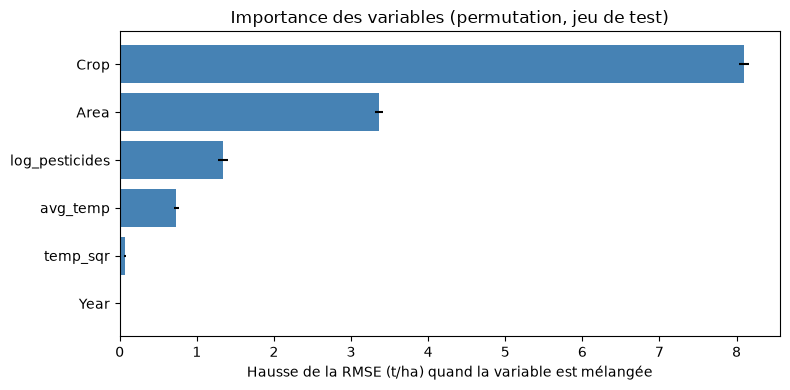

In [14]:
#Détermination de l'importance des variables : Permutation
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    modele_final, X_test_final, y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=10,
    random_state=SEED,
    n_jobs=-1,
)

importance_perm = pd.DataFrame({
    "variable": X_test_final.columns,
    "hausse_RMSE": perm.importances_mean,
    "ecart_type": perm.importances_std,
}).sort_values("hausse_RMSE", ascending=False)
display(importance_perm.round(3))

# Graphique
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importance_perm["variable"], importance_perm["hausse_RMSE"],
        xerr=importance_perm["ecart_type"], color="steelblue")
ax.invert_yaxis()  # la plus importante en haut
ax.set_xlabel("Hausse de la RMSE (t/ha) quand la variable est mélangée")
ax.set_title("Importance des variables (permutation, jeu de test)")
plt.tight_layout()
plt.show()

Le rendement dépend d’abord de la culture choisie, puis du pays, qui reflète les conditions de sol, d’irrigation et de savoir-faire locales. Parmi les facteurs sur lesquels l’agriculteur peut agir ou qu’il subit, le niveau d’intrants (pesticides) est le plus influent, suivi de la température, avec un optimum au-delà duquel le stress thermique réduit le rendement.

In [15]:
# Valeurs par défaut par pays : moyenne des 4 dernières années disponibles
df_pays = df.copy()
df_pays["pesticides_tonnes"] = np.expm1(df_pays["log_pesticides"])  # retour aux tonnes

# Une ligne par (pays, année) : pesticides et température sont identiques pour toutes les cultures
pays_annee = df_pays.drop_duplicates(subset=["Area", "Year"])[["Area", "Year", "avg_temp", "pesticides_tonnes"]]
dernieres_annees = pays_annee.sort_values("Year").groupby("Area").tail(4)

references_pays = (
    dernieres_annees.groupby("Area")
    .agg(
        avg_temp_defaut=("avg_temp", "mean"),
        pesticides_tonnes_defaut=("pesticides_tonnes", "mean"),
        derniere_annee=("Year", "max"),
    )
    .reset_index()
    .round(2)
)

display(references_pays.head())
print(len(references_pays), "pays")
references_pays.to_csv(MODELS_DIR / "references_pays.csv", index=False)

,Area,avg_temp_defaut,pesticides_tonnes_defaut,derniere_annee
0,Albania,16.77,1090.59,2013
1,Algeria,17.74,12454.01,2013
2,Angola,24.34,40.00,2013
3,Argentina,17.58,128617.57,2013
4,Armenia,10.38,278.72,2013


119 pays


In [4]:
# Couples (pays, culture) présents dans les données d'entraînement
references_pays_cultures = (
    train.groupby(["Area", "Crop"]).size()
    .rename("nb_annees")
    .reset_index()
)
display(references_pays_cultures.head())
print(len(references_pays_cultures), "couples pays-culture")
references_pays_cultures.to_csv(MODELS_DIR / "references_pays_cultures.csv", index=False)

,Area,Crop,nb_annees
0,Albania,Maize,20
1,Albania,Potatoes,20
2,Albania,Rice,4
3,Albania,Sorghum,3
4,Albania,Soybean,20


703 couples pays-culture
